In [1]:
import sounddevice as sd

In [2]:
import soundfile as sf

In [3]:
from pathlib import Path

In [4]:
import matplotlib.pyplot as plt

In [5]:
import numpy as np

In [6]:
from datetime import datetime

In [7]:
import pandas as pd

In [8]:
import time

In [8]:
# Project folders
OUTPUT_DIR = Path(
    r"D:\MachineSenseAI_project\data\raw\machine_01\healthy"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

METADATA_FILE = OUTPUT_DIR / "audio_metadata.csv"

# Recording settings
SAMPLE_RATE = 16000
DURATION = 5
NUM_SAMPLES = 20
CHANNELS = 1
MACHINE_ID = "M01"

metadata = []

print(sd.query_devices())
print("\nPrepare your YouTube motor audio.")
input("Press Enter when ready to record...")

for i in range(1, NUM_SAMPLES + 1):
    print(f"\nSample {i}/{NUM_SAMPLES}")
    print("Recording starts in 2 seconds...")
    time.sleep(2)

    # Timestamp immediately before recording
    timestamp = datetime.now().astimezone()
    timestamp_text = timestamp.isoformat(timespec="seconds")
    filename_time = timestamp.strftime("%Y%m%d_%H%M%S")

    filename = f"{MACHINE_ID}_H_{i:03d}_{filename_time}.wav"
    filepath = OUTPUT_DIR / filename

    try:
        audio = sd.rec(
            int(DURATION * SAMPLE_RATE),
            samplerate=SAMPLE_RATE,
            channels=CHANNELS,
            dtype="float32"
        )
        sd.wait()

        sf.write(filepath, audio, SAMPLE_RATE)

        metadata.append({
            "machine_id": MACHINE_ID,
            "filename": filename,
            "timestamp": timestamp_text,
            "duration_seconds": DURATION,
            "sample_rate_hz": SAMPLE_RATE,
            "label": "healthy_demo"
        })

        print(f"Saved: {filename}")
        print(f"Timestamp: {timestamp_text}")

    except Exception as e:
        print("Recording failed:", e)
        break

# Save metadata, including any successfully recorded samples
df = pd.DataFrame(metadata)

if METADATA_FILE.exists():
    df.to_csv(
        METADATA_FILE,
        mode="a",
        header=False,
        index=False
    )
else:
    df.to_csv(METADATA_FILE, index=False)

print("\nRecording finished.")
print("Successfully recorded:", len(metadata))
print("Metadata saved to:", METADATA_FILE)


   0 Microsoft Sound Mapper - Input, MME (2 in, 0 out)
>  1 Microphone Array (Realtek(R) Au, MME (2 in, 0 out)
   2 Microsoft Sound Mapper - Output, MME (0 in, 2 out)
<  3 Speaker/HP (Realtek(R) Audio), MME (0 in, 2 out)
   4 Primary Sound Capture Driver, Windows DirectSound (2 in, 0 out)
   5 Microphone Array (Realtek(R) Audio), Windows DirectSound (2 in, 0 out)
   6 Primary Sound Driver, Windows DirectSound (0 in, 2 out)
   7 Speaker/HP (Realtek(R) Audio), Windows DirectSound (0 in, 2 out)
   8 Speaker/HP (Realtek(R) Audio), Windows WASAPI (0 in, 2 out)
   9 Microphone Array (Realtek(R) Audio), Windows WASAPI (2 in, 0 out)
  10 Speakers (Realtek HD Audio output), Windows WDM-KS (0 in, 2 out)
  11 Microphone Array (Realtek HD Audio Mic input), Windows WDM-KS (2 in, 0 out)

Prepare your YouTube motor audio.


Press Enter when ready to record... 



Sample 1/20
Recording starts in 2 seconds...
Saved: M01_H_001_20261016_031522.wav
Timestamp: 2026-10-16T03:15:22-07:00

Sample 2/20
Recording starts in 2 seconds...
Saved: M01_H_002_20261016_031530.wav
Timestamp: 2026-10-16T03:15:30-07:00

Sample 3/20
Recording starts in 2 seconds...
Saved: M01_H_003_20261016_031537.wav
Timestamp: 2026-10-16T03:15:37-07:00

Sample 4/20
Recording starts in 2 seconds...
Saved: M01_H_004_20261016_031544.wav
Timestamp: 2026-10-16T03:15:44-07:00

Sample 5/20
Recording starts in 2 seconds...
Saved: M01_H_005_20261016_031552.wav
Timestamp: 2026-10-16T03:15:52-07:00

Sample 6/20
Recording starts in 2 seconds...
Saved: M01_H_006_20261016_031559.wav
Timestamp: 2026-10-16T03:15:59-07:00

Sample 7/20
Recording starts in 2 seconds...
Saved: M01_H_007_20261016_031606.wav
Timestamp: 2026-10-16T03:16:06-07:00

Sample 8/20
Recording starts in 2 seconds...
Saved: M01_H_008_20261016_031613.wav
Timestamp: 2026-10-16T03:16:13-07:00

Sample 9/20
Recording starts in 2 secon

In [9]:
DATA_DIR = Path(
    r"D:\MachineSenseAI_project\data\raw\machine_01\healthy"
)

metadata_path = DATA_DIR / "audio_metadata.csv"
df = pd.read_csv(metadata_path)

print("Total metadata records:", len(df))
print("Total WAV files:", len(list(DATA_DIR.glob("*.wav"))))
print("\nFirst 5 records:")
display(df.head())

# Check duration and sample rate of each recording
for filename in df["filename"]:
    filepath = DATA_DIR / filename

    if filepath.exists():
        info = sf.info(filepath)
        print(
            f"{filename} | "
            f"Duration: {info.duration:.2f}s | "
            f"Sample rate: {info.samplerate} Hz"
        )
    else:
        print("MISSING FILE:", filename)


Total metadata records: 20
Total WAV files: 30

First 5 records:


,machine_id,filename,timestamp,duration_seconds,sample_rate_hz,label
0,M01,M01_H_001_20261016_031522.wav,2026-10-16T03:15:22-07:00,5,16000,healthy_demo
1,M01,M01_H_002_20261016_031530.wav,2026-10-16T03:15:30-07:00,5,16000,healthy_demo
2,M01,M01_H_003_20261016_031537.wav,2026-10-16T03:15:37-07:00,5,16000,healthy_demo
3,M01,M01_H_004_20261016_031544.wav,2026-10-16T03:15:44-07:00,5,16000,healthy_demo
4,M01,M01_H_005_20261016_031552.wav,2026-10-16T03:15:52-07:00,5,16000,healthy_demo


M01_H_001_20261016_031522.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_002_20261016_031530.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_003_20261016_031537.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_004_20261016_031544.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_005_20261016_031552.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_006_20261016_031559.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_007_20261016_031606.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_008_20261016_031613.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_009_20261016_031621.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_010_20261016_031628.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_011_20261016_031635.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_012_20261016_031642.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_013_20261016_031650.wav | Duration: 5.00s | Sample rate: 16000 Hz
M01_H_014_20261016_031657.wav | Duration: 5.00s | Sample rate: 1

In [10]:
import librosa

# Project paths
DATA_DIR = Path(
    r"D:\MachineSenseAI_project\data\raw\machine_01\healthy"
)

METADATA_FILE = DATA_DIR / "audio_metadata.csv"
OUTPUT_FILE = Path(
    r"D:\MachineSenseAI_project\data\audio_features.csv"
)

# Load recording metadata
metadata = pd.read_csv(METADATA_FILE)

feature_rows = []

def extract_features(filepath):
    audio, sr = sf.read(filepath, dtype="float32")

    # Convert stereo to mono if necessary
    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    # Basic audio checks
    if len(audio) == 0:
        raise ValueError("Audio file is empty")

    if not np.isfinite(audio).all():
        raise ValueError("Audio contains invalid values")

    # RMS: sound energy
    rms = librosa.feature.rms(y=audio)

    # ZCR: rate of signal sign changes
    zcr = librosa.feature.zero_crossing_rate(y=audio)

    # Frequency-based features
    centroid = librosa.feature.spectral_centroid(
        y=audio, sr=sr
    )
    bandwidth = librosa.feature.spectral_bandwidth(
        y=audio, sr=sr
    )
    rolloff = librosa.feature.spectral_rolloff(
        y=audio, sr=sr
    )
    flatness = librosa.feature.spectral_flatness(y=audio)

    # MFCCs: compact representation of the sound spectrum
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    features = {
        "duration_seconds": len(audio) / sr,
        "sample_rate_hz": sr,
        "audio_rms_mean": float(np.mean(rms)),
        "audio_rms_std": float(np.std(rms)),
        "zcr_mean": float(np.mean(zcr)),
        "zcr_std": float(np.std(zcr)),
        "centroid_mean": float(np.mean(centroid)),
        "centroid_std": float(np.std(centroid)),
        "bandwidth_mean": float(np.mean(bandwidth)),
        "rolloff_mean": float(np.mean(rolloff)),
        "flatness_mean": float(np.mean(flatness)),
    }

    # Mean and standard deviation of each of 13 MFCCs
    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = float(
            np.mean(mfcc[i])
        )
        features[f"mfcc_{i+1}_std"] = float(
            np.std(mfcc[i])
        )

    return features


for _, row in metadata.iterrows():
    filepath = DATA_DIR / row["filename"]

    if not filepath.exists():
        print("Missing file:", filepath.name)
        continue

    try:
        features = extract_features(filepath)

        # Preserve the original sample identity and timestamp
        features["machine_id"] = row["machine_id"]
        features["filename"] = row["filename"]
        features["timestamp"] = row["timestamp"]
        features["label"] = row["label"]

        feature_rows.append(features)
        print("Processed:", filepath.name)

    except Exception as e:
        print(f"Failed on {filepath.name}: {e}")

# Save all successfully processed recordings
features_df = pd.DataFrame(feature_rows)
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
features_df.to_csv(OUTPUT_FILE, index=False)

print("\nFeature extraction completed.")
print("Successfully processed:", len(features_df))
print("Feature columns:", len(features_df.columns))
print("Saved to:", OUTPUT_FILE)

display(features_df.head())


Processed: M01_H_001_20261016_031522.wav
Processed: M01_H_002_20261016_031530.wav
Processed: M01_H_003_20261016_031537.wav
Processed: M01_H_004_20261016_031544.wav
Processed: M01_H_005_20261016_031552.wav
Processed: M01_H_006_20261016_031559.wav
Processed: M01_H_007_20261016_031606.wav
Processed: M01_H_008_20261016_031613.wav
Processed: M01_H_009_20261016_031621.wav
Processed: M01_H_010_20261016_031628.wav
Processed: M01_H_011_20261016_031635.wav
Processed: M01_H_012_20261016_031642.wav
Processed: M01_H_013_20261016_031650.wav
Processed: M01_H_014_20261016_031657.wav
Processed: M01_H_015_20261016_031704.wav
Processed: M01_H_016_20261016_031711.wav
Processed: M01_H_017_20261016_031719.wav
Processed: M01_H_018_20261016_031726.wav
Processed: M01_H_019_20261016_031733.wav
Processed: M01_H_020_20261016_031740.wav

Feature extraction completed.
Successfully processed: 20
Feature columns: 41
Saved to: D:\MachineSenseAI_project\data\audio_features.csv


,duration_seconds,sample_rate_hz,audio_rms_mean,audio_rms_std,zcr_mean,zcr_std,centroid_mean,centroid_std,bandwidth_mean,rolloff_mean,...,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,machine_id,filename,timestamp,label
0,5.0,16000,0.350492,0.080347,0.354312,0.080469,3395.352133,181.594648,1962.438394,5536.425159,...,-4.703500,8.081001,-0.330512,5.539989,3.447190,3.612468,M01,M01_H_001_20261016_031522.wav,2026-10-16T03:15:22-07:00,healthy_demo
1,5.0,16000,0.409201,0.065048,0.381522,0.055728,3598.523030,126.561853,1949.729095,5721.586385,...,-15.885979,4.191828,-7.372024,4.951259,12.370031,2.592127,M01,M01_H_002_20261016_031530.wav,2026-10-16T03:15:30-07:00,healthy_demo
2,5.0,16000,0.396435,0.021929,0.395747,0.031010,3634.598677,69.299294,1927.697636,5716.759554,...,-16.227404,4.393280,-10.575799,4.714284,13.478017,2.739162,M01,M01_H_003_20261016_031537.wav,2026-10-16T03:15:37-07:00,healthy_demo
3,5.0,16000,0.374072,0.024319,0.409404,0.027083,3657.552614,50.099676,1874.578414,5704.667596,...,-25.545534,3.066906,-1.367409,2.789685,8.577803,3.428356,M01,M01_H_004_20261016_031544.wav,2026-10-16T03:15:44-07:00,healthy_demo
4,5.0,16000,0.389856,0.025837,0.398546,0.030266,3642.360154,87.166537,1897.958397,5715.764331,...,-23.827274,4.370517,-3.498017,4.526240,10.473128,3.775155,M01,M01_H_005_20261016_031552.wav,2026-10-16T03:15:52-07:00,healthy_demo


In [11]:
FEATURE_FILE = Path(
    r"D:\MachineSenseAI_project\data\audio_features.csv"
)

df = pd.read_csv(FEATURE_FILE)

print("Dataset shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("\nFeature summary:")
display(
    df[[
        "audio_rms_mean",
        "zcr_mean",
        "centroid_mean",
        "bandwidth_mean",
        "flatness_mean"
    ]].describe()
)


Dataset shape: (20, 41)

Missing values: 0

Feature summary:


,audio_rms_mean,zcr_mean,centroid_mean,bandwidth_mean,flatness_mean
count,20.000000,20.000000,20.000000,20.000000,20.000000
mean,0.359430,0.383402,3550.344533,1919.305798,0.175935
std,0.060897,0.043630,272.991270,25.762641,0.022372
min,0.117053,0.208583,2420.401516,1874.578414,0.092472
25%,0.351765,0.381664,3594.709190,1900.509091,0.172411
50%,0.370664,0.396343,3622.637205,1916.644202,0.179765
75%,0.391250,0.399651,3646.771275,1938.897235,0.186945
max,0.409201,0.410358,3666.817831,1964.416253,0.199334


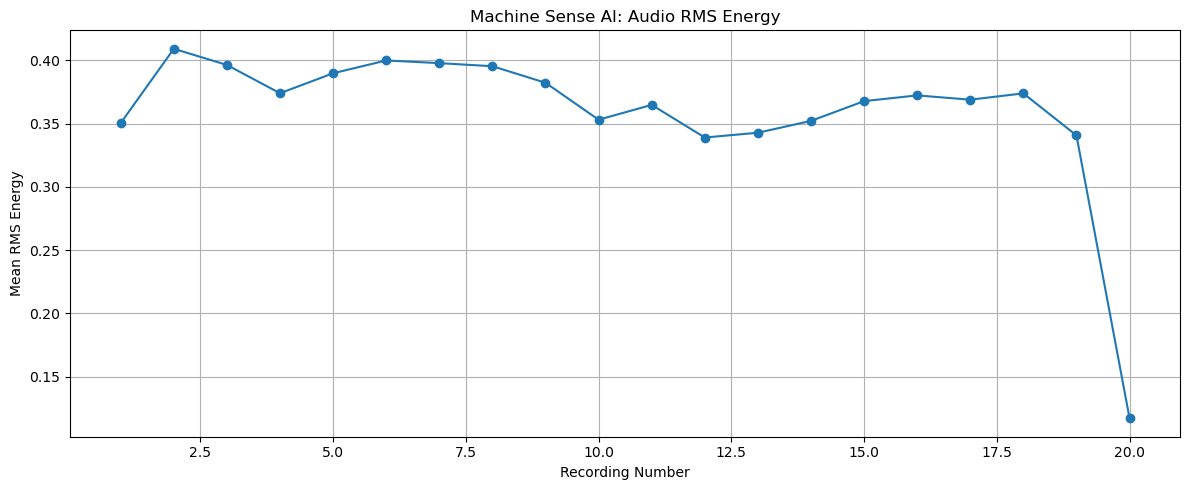

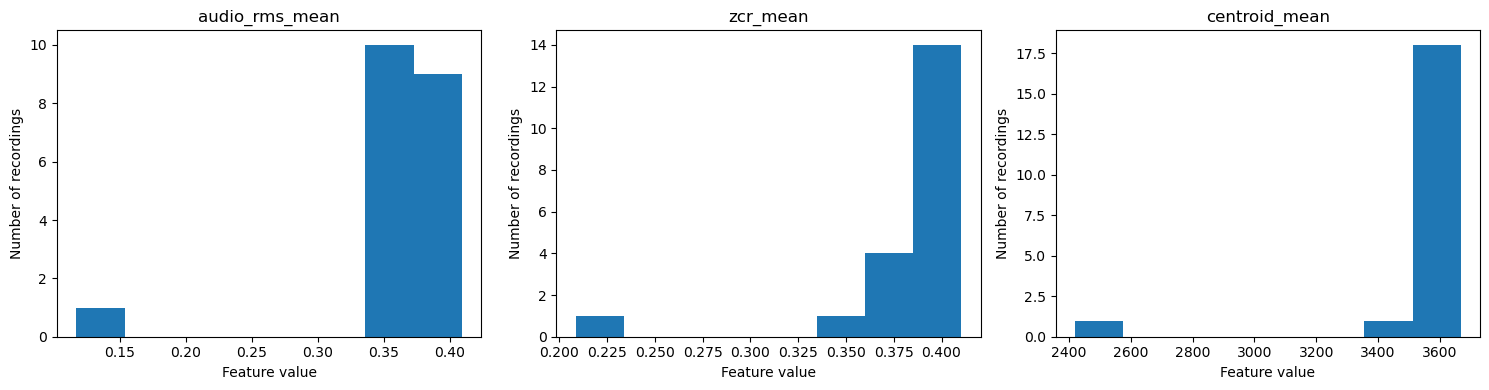

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(
    range(1, len(df) + 1),
    df["audio_rms_mean"],
    marker="o"
)
plt.title("Machine Sense AI: Audio RMS Energy")
plt.xlabel("Recording Number")
plt.ylabel("Mean RMS Energy")
plt.grid(True)
plt.tight_layout()
plt.show()

# Compare three important features
features_to_plot = [
    "audio_rms_mean",
    "zcr_mean",
    "centroid_mean"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, features_to_plot):
    ax.hist(df[feature].dropna(), bins=8)
    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Number of recordings")

plt.tight_layout()
plt.show()


In [13]:

from pathlib import Path
import pandas as pd
import numpy as np
import joblib

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Paths
FEATURE_FILE = Path(
    r"D:\MachineSenseAI_project\data\audio_features.csv"
)
MODEL_DIR = Path(r"D:\MachineSenseAI_project\models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = MODEL_DIR / "audio_isolation_forest.joblib"

# Load features
df = pd.read_csv(FEATURE_FILE)

# Select numerical audio features only
exclude_columns = [
    "machine_id", "filename", "timestamp", "label"
]
feature_columns = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in exclude_columns
]

X = df[feature_columns].replace([np.inf, -np.inf], np.nan)

if len(X) < 5:
    raise ValueError("Not enough audio samples to train the model.")

# Build preprocessing + anomaly detection pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("isolation_forest", IsolationForest(
        n_estimators=200,
        contamination=0.10,
        random_state=42
    ))
])

# Train on the healthy-demo recordings
model.fit(X)

# Predict on the training samples
predictions = model.predict(X)
scores = model.decision_function(X)

df["anomaly_prediction"] = predictions
df["anomaly_score"] = scores

print("Training completed!")
print("Total samples:", len(X))
print("Features used:", len(feature_columns))
print("Flagged as anomalies:", int((predictions == -1).sum()))
print("Saved model to:", MODEL_FILE)

# Save model and the feature-column order
joblib.dump({
    "pipeline": model,
    "feature_columns": feature_columns
}, MODEL_FILE)

# Save demo results
RESULT_FILE = Path(
    r"D:\MachineSenseAI_project\data\audio_training_results.csv"
)
df.to_csv(RESULT_FILE, index=False)

display(df[[
    "filename", "anomaly_prediction", "anomaly_score"
]].head(10))


Training completed!
Total samples: 20
Features used: 37
Flagged as anomalies: 2
Saved model to: D:\MachineSenseAI_project\models\audio_isolation_forest.joblib


,filename,anomaly_prediction,anomaly_score
0,M01_H_001_20261016_031522.wav,-1,-0.019942
1,M01_H_002_20261016_031530.wav,1,0.074746
2,M01_H_003_20261016_031537.wav,1,0.137032
3,M01_H_004_20261016_031544.wav,1,0.112576
4,M01_H_005_20261016_031552.wav,1,0.118619
5,M01_H_006_20261016_031559.wav,1,0.134327
6,M01_H_007_20261016_031606.wav,1,0.130817
7,M01_H_008_20261016_031613.wav,1,0.139433
8,M01_H_009_20261016_031621.wav,1,0.131976
9,M01_H_010_20261016_031628.wav,1,0.002216


In [14]:
SAMPLE_RATE = 16000
DURATION = 5

TEST_DIR = Path(r"D:\Machine_Sense_AI\data\test")
TEST_DIR.mkdir(parents=True, exist_ok=True)

test_path = TEST_DIR / "new_motor.wav"

input("Start your motor audio, then press Enter to record...")

print("Recording for 5 seconds...")
audio = sd.rec(
    int(SAMPLE_RATE * DURATION),
    samplerate=SAMPLE_RATE,
    channels=1,
    dtype="float32"
)
sd.wait()

sf.write(test_path, audio, SAMPLE_RATE)

print("Saved test recording:", test_path)


Start your motor audio, then press Enter to record... 


Recording for 5 seconds...
Saved test recording: D:\Machine_Sense_AI\data\test\new_motor.wav


In [15]:
MODEL_FILE = Path(
    r"D:\Machine_Sense_AI\models\audio_isolation_forest.joblib"
)
TEST_FILE = Path(
    r"D:\Machine_Sense_AI\data\test\new_motor.wav"
)

# Load the saved model
saved = joblib.load(MODEL_FILE)
model = saved["pipeline"]
feature_columns = saved["feature_columns"]

# Reuse the extract_features() function from Stage 2
features = extract_features(TEST_FILE)

# Match the exact training feature order
X_new = pd.DataFrame(
    [[features[col] for col in feature_columns]],
    columns=feature_columns
)

prediction = model.predict(X_new)[0]
score = model.decision_function(X_new)[0]

print("Prediction:", prediction)
print("Anomaly score:", round(float(score), 4))

if prediction == 1:
    print("Result: Not flagged as anomalous.")
else:
    print("Result: Unusual audio detected; review this recording.")

print("\nNote: This is a demo result, not a confirmed motor-fault diagnosis.")


Prediction: -1
Anomaly score: -0.091
Result: Unusual audio detected; review this recording.

Note: This is a demo result, not a confirmed motor-fault diagnosis.
